# Campos de Direções (Retrato de Fase do Sistema)

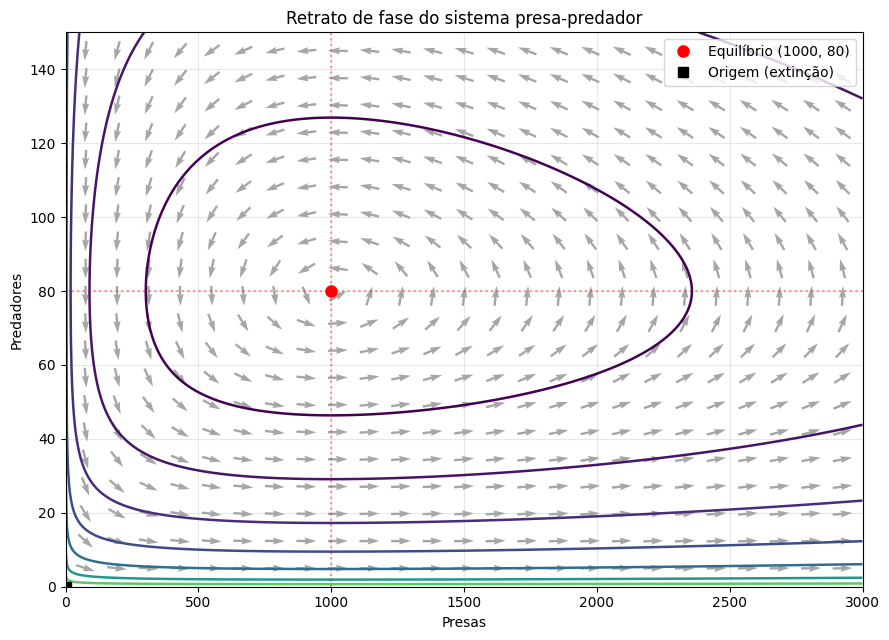

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros do sistema presa-predador
k, a = 0.08, 0.001      # presas: crescimento e predação
r, b = 0.02, 0.00002    # predadores: mortalidade e ganho por predação

def sistema(x, y):
    dx = k * x - a * x * y
    dy = -r * y + b * x * y
    return dx, dy

def H(x, y):  # quantidade conservada (curvas de nível = órbitas)
    return b * x - r * np.log(x) + a * y - k * np.log(y)

# Janela de visualização
x_min, x_max = 0, 3000
y_min, y_max = 0, 150

x_eq, y_eq = r / b, k / a   # (1000, 80)

fig, ax = plt.subplots(figsize = (9, 6.5))

# 1) Campo de direções normalizado (em coordenadas de TELA)
xs = np.linspace(x_min + 75, x_max - 75, 25)
ys = np.linspace(y_min + 5, y_max - 5, 20)
X, Y = np.meshgrid(xs, ys)
U, V = sistema(X, Y)

# normalizar considerando a escala dos eixos, para que as setas
# tenham o mesmo comprimento visual e a direção correta na tela
Us = U / (x_max - x_min)
Vs = V / (y_max - y_min)
N = np.hypot(Us, Vs)
N[N == 0] = 1
ax.quiver(X, Y, Us / N, Vs / N, angles = "uv", color = "gray",
          alpha = 0.7, pivot = "mid", width = 0.003)

# 2) Órbitas: curvas de nível de H (começando em x, y > 0 para evitar log(0))
xx = np.linspace(1, x_max, 800)
yy = np.linspace(0.5, y_max, 800)
XX, YY = np.meshgrid(xx, yy)
HH = H(XX, YY)

H_eq = H(x_eq, y_eq)
niveis = H_eq + np.array([0.01, 0.03, 0.06, 0.1, 0.15, 0.22, 0.3, 0.4])
ax.contour(XX, YY, HH, levels = niveis, cmap = "viridis", linewidths = 1.8)

# 3) Pontos de equilíbrio e eixos invariantes
ax.plot(x_eq, y_eq, "ro", ms = 8, label = f"Equilíbrio ({x_eq:.0f}, {y_eq:.0f})")
ax.plot(0, 0, "ks", ms = 7, label = "Origem (extinção)")
ax.axvline(x_eq, color = "r", ls = ":", alpha = 0.4)   # x' = 0 em y = y_eq e y' = 0 em x = x_eq
ax.axhline(y_eq, color = "r", ls = ":", alpha = 0.4)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Presas")
ax.set_ylabel("Predadores")
ax.set_title("Retrato de fase do sistema presa-predador")
ax.grid(True, alpha = 0.3)
ax.legend(loc = "upper right")
plt.tight_layout()
plt.show()

# Gráficos das Populações de Coelhos e Lobos como Função do Tempo (Método de Runge-Kutta de Quarta Ordem)

Os métodos de Runge-Kutta de ordem $m$ fornecem valores aproximados da solução do problema de valor inicial

$$
\left\{\begin{array}{l}
y^{\prime}=F(x,y)\\
y(x_{0})=y_{0}
\end{array} \right.
,
$$

que coincidem comos valores obtidos através da expansão em série de Taylor de $y$, em torno do ponto $x$, até o termo que inclui $h^{m}$, ou seja,

$$y(x+h)\approx{}y(x)+hf(x,y(x))+\frac{h^{2}}{2!}f^{\prime}(x,y(x))+\cdots+\frac{h^{m}}{m!}f^{(m-1)}(x,y(x)).$$

Nestes métodos o cálculo do valor das derivadas da função $f(x,y(x))$ nos pontos $(x_{n},y_{n})$ será substituído pelo cálculo da função $f(x,y)$ em pontos convenientes, produzindo resultados equivalentes.

O método de Runge-Kutta de ordem $m=1$ recai no método de Euler.

O método de Runge-Kutta de quarta ordem é definido pelas equações

$$y_{n}=y_{n-1}+\frac{h}{6}(K_{1}+2K_{2}+2K_{3}+K_{4}), \qquad n=1,2,\ldots,N,$$

em que

$$K_{1}=F(x_{n-1},y_{n-1}), \qquad K_{2}=F\left(x_{n-1}+\frac{h}{2},y_{n-1}+\frac{h}{2}K_{1}\right),$$

$$K_{3}=F\left(x_{n-1}+\frac{h}{2},y_{n-1}+\frac{h}{2}K_{2}\right), \qquad K_{4}=F(x_{n-1}+h,y_{n-1}+hK_{3}).$$

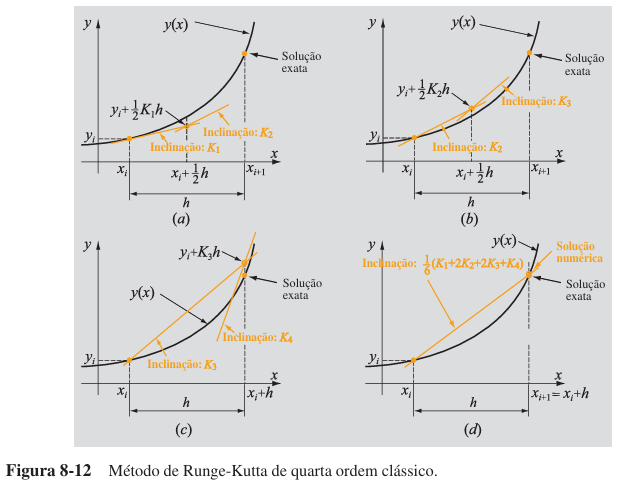

## Exemplo 1.

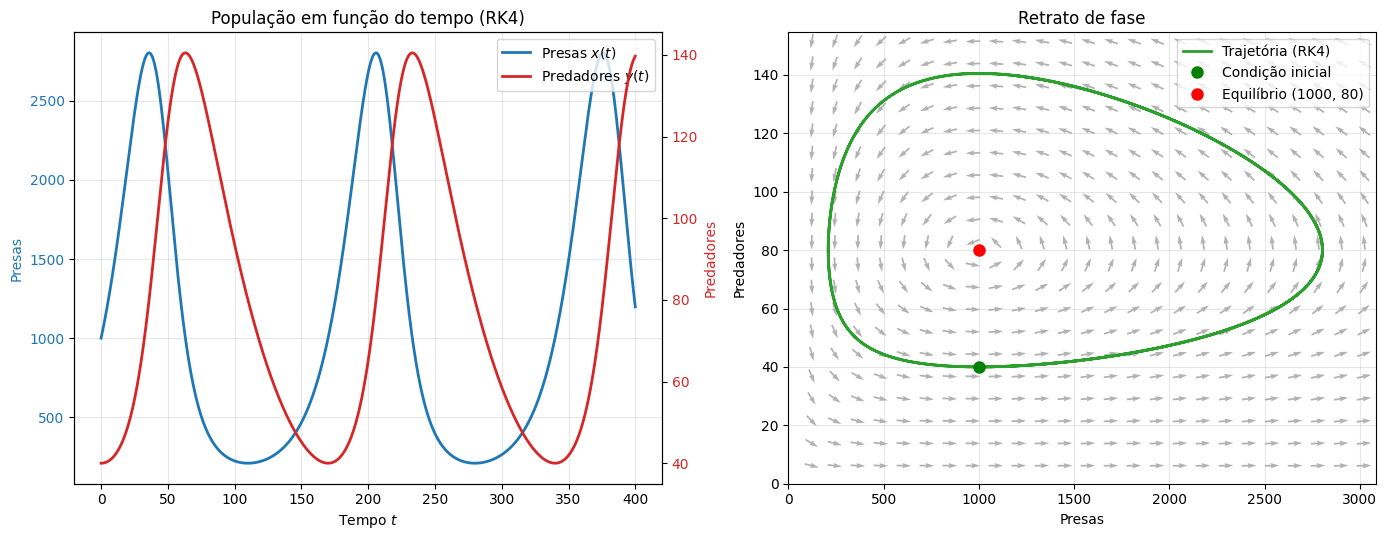

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- Parâmetros do sistema ----------------

k, a = 0.08, 0.001      # presas: crescimento e predação
r, b = 0.02, 0.00002    # predadores: mortalidade e ganho por predação

def F(t, z):
    x, y = z
    return np.array([k * x - a * x * y,
                     -r * y + b * x * y])

# ---------------- Método de Runge-Kutta de 4ª ordem ----------------

def rk4(F, z0, t0, tf, h):
    t = np.arange(t0, tf+h, h)
    N = len(t) - 1

    Z = np.full((N+1, 2), np.nan)

    Z[0] = z0
    for n in range(1, N+1):
        K1 = F(t[n-1], Z[n-1])
        K2 = F(t[n-1] + h / 2, Z[n-1] + h / 2 * K1)
        K3 = F(t[n-1] + h / 2, Z[n-1] + h / 2 * K2)
        K4 = F(t[n-1] + h, Z[n-1] + h * K3)
        Z[n] = Z[n-1] + (h / 6) * (K1 + 2 * K2 + 2 * K3 + K4)
    return t, Z

# ---------------- Condições iniciais e passo ----------------

x0, y0 = 1000, 40        # presas e predadores iniciais
t0, tf = 0, 400          # intervalo de tempo
h = 0.1                  # passo

t, Z = rk4(F, np.array([x0, y0], dtype = float), t0, tf, h)
x, y = Z[:, 0], Z[:, 1]

# ---------------- Figura ----------------

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5.5))

# (1) Presa e predador em função do tempo, no mesmo gráfico
#     (eixo y secundário, pois as escalas são muito diferentes)
cor_presa, cor_pred = "tab:blue", "tab:red"
l1, = ax1.plot(t, x, color=cor_presa, lw = 2, label = "Presas $x(t)$")
ax1.set_xlabel("Tempo $t$")
ax1.set_ylabel("Presas", color = cor_presa)
ax1.tick_params(axis = "y", labelcolor = cor_presa)

ax1b = ax1.twinx()
l2, = ax1b.plot(t, y, color = cor_pred, lw = 2, label = "Predadores $y(t)$")
ax1b.set_ylabel("Predadores", color = cor_pred)
ax1b.tick_params(axis = "y", labelcolor = cor_pred)

ax1.set_title("População em função do tempo (RK4)")
ax1.grid(True, alpha = 0.3)
ax1.legend(handles = [l1, l2], loc = "upper right")

# (2) Retrato de fase com campo de direções e trajetória
xmax = 1.1 * x.max()
ymax = 1.1 * y.max()

xs = np.linspace(0.04 * xmax, 0.98 * xmax, 25)
ys = np.linspace(0.04 * ymax, 0.98 * ymax, 20)
X, Y = np.meshgrid(xs, ys)
U = k * X - a * X * Y
V = -r * Y + b * X * Y

# normalização em coordenadas de tela (setas de mesmo tamanho visual)
Us, Vs = U / xmax, V / ymax
N = np.hypot(Us, Vs)
N[N == 0] = 1
ax2.quiver(X, Y, Us / N, Vs / N, angles = "uv", color = "gray",
           alpha = 0.6, pivot = "mid", width = 0.003)

ax2.plot(x, y, color = "tab:green", lw = 2, label = "Trajetória (RK4)")
ax2.plot(x0, y0, "go", ms = 8, label = "Condição inicial")
ax2.plot(r / b, k / a, "ro", ms = 8, label = f"Equilíbrio ({r / b:.0f}, {k / a:.0f})")

ax2.set_xlim(0, xmax)
ax2.set_ylim(0, ymax)
ax2.set_xlabel("Presas")
ax2.set_ylabel("Predadores")
ax2.set_title("Retrato de fase")
ax2.grid(True, alpha = 0.3)
ax2.legend(loc = "upper right")

plt.tight_layout()
plt.show()

# Referências

[1] Humes, A. F. P. C., Melo, I. S. H., Yoshida, L. K., \& Martins, W. T. (1984). *Noções de Cálculo Numérico*. São Paulo: McGraw-Hill do Brasil. v. 1. 201 p.

[2] Gilat, A., \& Subramaniam, V. (2009). *Métodos Numéricos para Engenheiros e Cientistas: Uma Introdução com Aplicações Usando o MATLAB*. Grupo A - Bookman.